# COQE (Container and Quantity Estimation)

> RGB images of containers with varying liquid content for quantity estimation and related reasoning tasks.

**GT available (per image):**
- Container bounding box (`x1,y1,x2,y2`)
- Container category (`category`) and content level (`content`)
- Volume labels: continuous (`volume_continuous`), discrete (`volume_discrete`), comparative (`comparative_vol`)
- CAD model id (`cad_model`) and optional pour prediction labels (angle + `t0..t4` content values)

In [3]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np
from PIL import Image

# Setup paths
data_root = Path("..") / "data" / "COQE_dataset"
images_dir = data_root / "images"
cad_models_dir = data_root / "cad_models"

print(f"Dataset root: {data_root}")
print(f"Images directory: {images_dir}")
print(f"CAD models directory: {cad_models_dir}")

Dataset root: ../data/COQE_dataset
Images directory: ../data/COQE_dataset/images
CAD models directory: ../data/COQE_dataset/cad_models


## Load Dataset Annotations

In [4]:
# Load training annotations
with open(data_root / "train.json", "r") as f:
    train_data = json.load(f)

with open(data_root / "train_pour_prediction.json", "r") as f:
    train_pour_data = json.load(f)

# Load testing annotations
with open(data_root / "test.json", "r") as f:
    test_data = json.load(f)

with open(data_root / "test_pour_prediction.json", "r") as f:
    test_pour_data = json.load(f)

print(f"Training samples: {len(train_data)}")
print(f"Training pour prediction samples: {len(train_pour_data)}")
print(f"Test samples: {len(test_data)}")
print(f"Test pour prediction samples: {len(test_pour_data)}")

Training samples: 6386
Training pour prediction samples: 31930
Test samples: 3000
Test pour prediction samples: 15000


## Dataset Statistics

In [5]:
# Analyze dataset statistics
categories = {}
cad_models = set()
content_levels = []

for sample in train_data:
    cat = sample.get("category", "unknown")
    categories[cat] = categories.get(cat, 0) + 1
    cad_models.add(sample.get("cad_model"))
    content_levels.append(sample.get("content", 0))

print("\n=== Dataset Statistics ===")
print(f"\nCategories in training set:")
for cat, count in sorted(categories.items(), key=lambda x: -x[1]):
    print(f"  {cat}: {count}")

print(f"\nUnique CAD models: {len(cad_models)}")
print(f"Content level range: {min(content_levels)} to {max(content_levels)}")
print(f"Average content level: {np.mean(content_levels):.2f}")


=== Dataset Statistics ===

Categories in training set:
  bottle: 2653
  toiletry: 1083
  glass: 506
  other: 499
  mug: 357
  jar: 252
  can: 238
  dinnerware: 230
  disposable_cup: 222
  pitcher: 162
  cookware: 106
  vase: 78

Unique CAD models: 34
Content level range: 1 to 6
Average content level: 4.28


## Visualization Helper Functions

In [6]:
def visualize_sample(sample, pour_sample=None, title_prefix=""):
    """Visualize a single COQE dataset sample with annotations."""
    
    # Load image
    image_path = images_dir / sample["image_id"]
    img = Image.open(image_path)
    img_array = np.array(img)
    
    # Create figure
    if pour_sample:
        fig, axes = plt.subplots(1, 2, figsize=(16, 7))
    else:
        fig, axes = plt.subplots(1, 1, figsize=(10, 7))
        axes = [axes]
    
    # Plot image with bounding box
    ax = axes[0]
    ax.imshow(img_array)
    
    # Draw bounding box
    x1, y1, x2, y2 = sample["x1"], sample["y1"], sample["x2"], sample["y2"]
    width = x2 - x1
    height = y2 - y1
    rect = patches.Rectangle((x1, y1), width, height, 
                             linewidth=3, edgecolor='lime', facecolor='none')
    ax.add_patch(rect)
    
    # Add text annotations
    ax.text(x1, y1 - 10, f"CAD Model: {sample['cad_model']}", 
           fontsize=10, color='white', backgroundcolor='black',
           bbox=dict(boxstyle='round', facecolor='black', alpha=0.7))
    
    ax.set_title(f"{title_prefix} - {sample['image_id']}", fontsize=14, fontweight='bold')
    ax.axis('off')
    
    # Add metadata text
    metadata_text = f"""
Category: {sample.get('category', 'N/A')}
Content Level: {sample.get('content', 'N/A')}
Volume (Continuous): {sample.get('volume_continuous', 'N/A')}
Volume (Discrete): {sample.get('volume_discrete', 'N/A')}
Comparative Volume: {sample.get('comparative_vol', 'N/A')}
Bounding Box: ({x1}, {y1}) to ({x2}, {y2})
CAD Model ID: {sample.get('cad_model', 'N/A')}
    """
    
    # Display metadata in a text box below the image
    props = dict(boxstyle='round', facecolor='wheat', alpha=0.8)
    ax.text(0.02, -0.15, metadata_text.strip(), transform=ax.transAxes,
           fontsize=10, verticalalignment='top', bbox=props, family='monospace')
    
    # Plot pour prediction data if available
    if pour_sample:
        ax2 = axes[1]
        
        # Visualize temporal content prediction
        time_steps = ['t0', 't1', 't2', 't3', 't4']
        content_values = [pour_sample.get(f'{t}_content', 0) for t in time_steps]
        
        # Create bar plot
        bars = ax2.bar(time_steps, content_values, color='steelblue', alpha=0.7, edgecolor='black')
        ax2.set_xlabel('Time Step', fontsize=12)
        ax2.set_ylabel('Content Level', fontsize=12)
        ax2.set_title(f'Pour Prediction (Angle: {pour_sample.get("angle", "N/A")}°)', 
                     fontsize=14, fontweight='bold')
        ax2.set_ylim(0, max(content_values) + 2 if content_values else 15)
        ax2.grid(axis='y', alpha=0.3)
        
        # Add value labels on bars
        for bar, val in zip(bars, content_values):
            height = bar.get_height()
            ax2.text(bar.get_x() + bar.get_width()/2., height,
                   f'{val}', ha='center', va='bottom', fontsize=10)
        
        # Add pour prediction metadata
        pour_text = f"""
Pouring Angle: {pour_sample.get('angle', 'N/A')}°
Image ID: {pour_sample.get('image_id', 'N/A')}

Content Prediction Over Time:
  t0 (initial): {content_values[0]}
  t1: {content_values[1]}
  t2: {content_values[2]}
  t3: {content_values[3]}
  t4 (final): {content_values[4]}
        """
        
        props2 = dict(boxstyle='round', facecolor='lightblue', alpha=0.8)
        ax2.text(0.02, -0.25, pour_text.strip(), transform=ax2.transAxes,
               fontsize=10, verticalalignment='top', bbox=props2, family='monospace')
    
    plt.tight_layout()
    plt.show()

def find_pour_sample(image_id, pour_data_list):
    """Find a pour prediction sample matching the image_id."""
    for sample in pour_data_list:
        if sample.get('image_id') == image_id:
            return sample
    return None

## Training Sample Visualization

Let's visualize a representative training sample with all available information.

Training Sample #10
Image: 10362.png
Has pour prediction: True


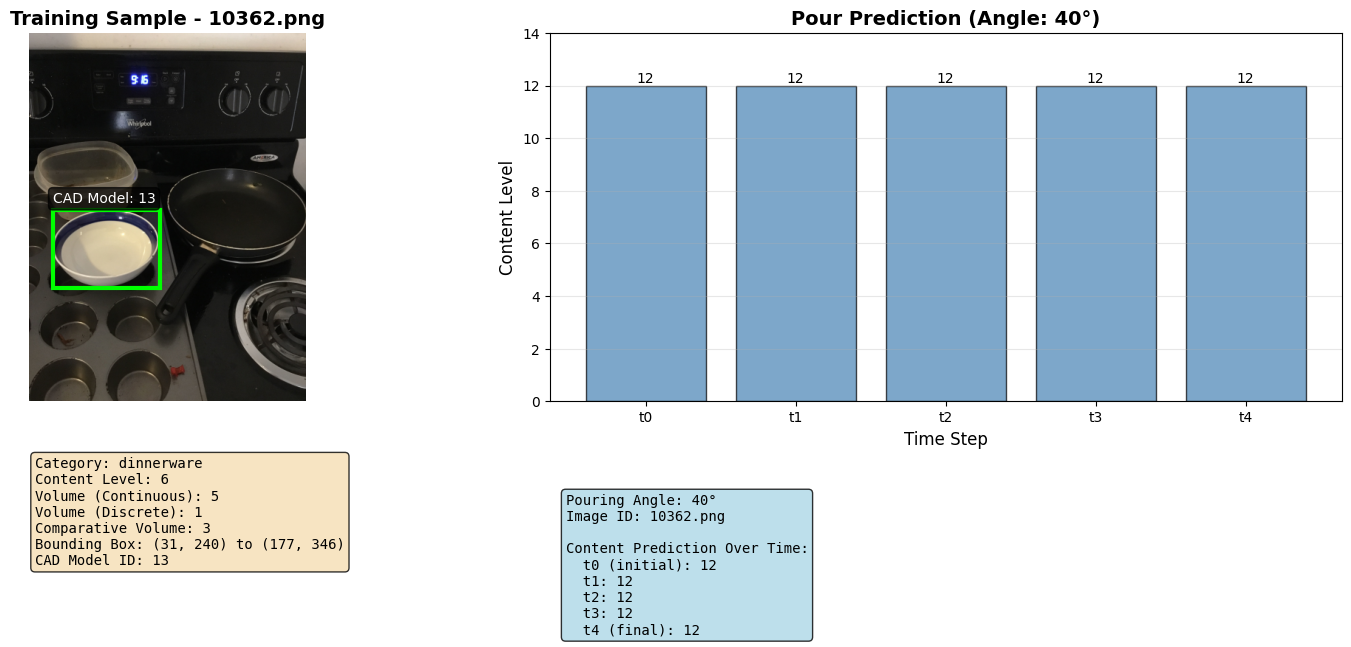

In [7]:
# Select an interesting training sample (one with intermediate content level)
train_sample_idx = 10  # You can change this to explore different samples
train_sample = train_data[train_sample_idx]

# Find corresponding pour prediction
train_pour_sample = find_pour_sample(train_sample["image_id"], train_pour_data)

print(f"Training Sample #{train_sample_idx}")
print(f"Image: {train_sample['image_id']}")
print(f"Has pour prediction: {train_pour_sample is not None}")

visualize_sample(train_sample, train_pour_sample, title_prefix="Training Sample")

## Testing Sample Visualization

Now let's visualize a testing sample.

Test Sample #5
Image: 01793.png
Has pour prediction: True


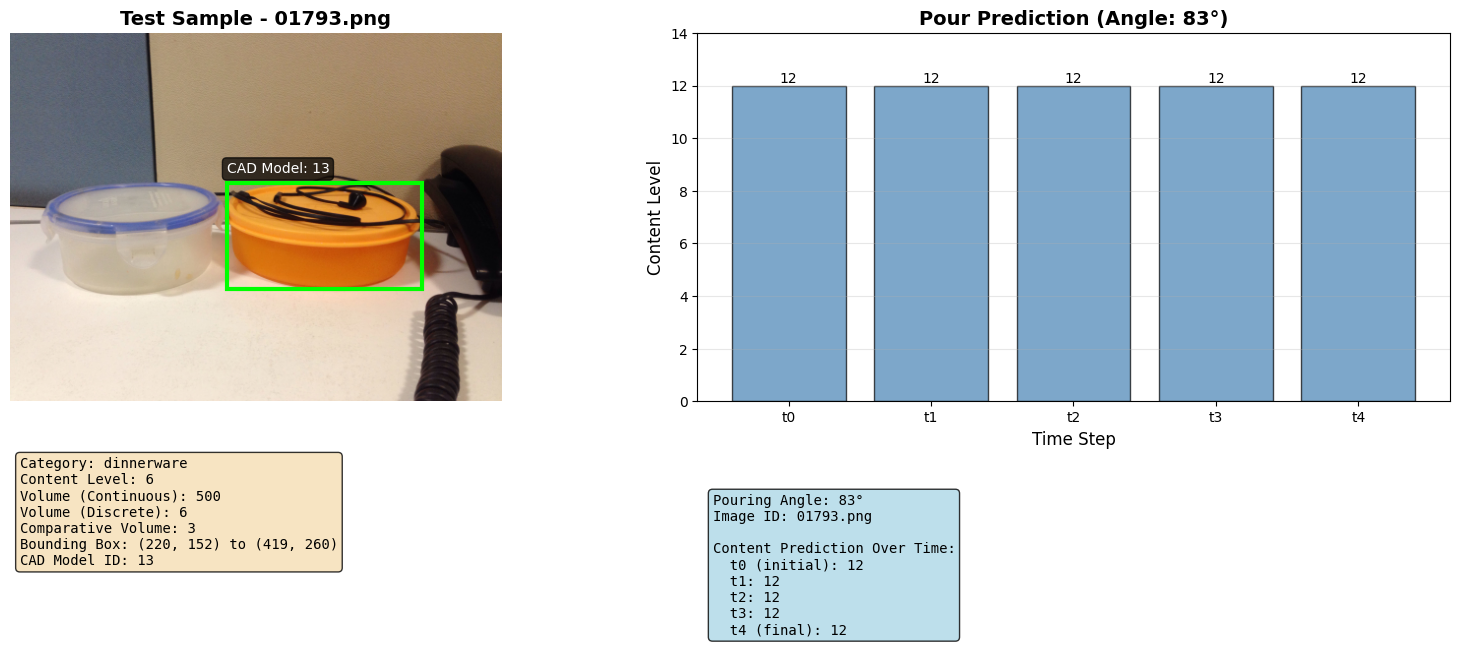

In [8]:
# Select a test sample
test_sample_idx = 5  # You can change this to explore different samples
test_sample = test_data[test_sample_idx]

# Find corresponding pour prediction
test_pour_sample = find_pour_sample(test_sample["image_id"], test_pour_data)

print(f"Test Sample #{test_sample_idx}")
print(f"Image: {test_sample['image_id']}")
print(f"Has pour prediction: {test_pour_sample is not None}")

visualize_sample(test_sample, test_pour_sample, title_prefix="Test Sample")

## Explore Multiple Samples

Visualize several samples to get a better sense of the dataset diversity.

=== Multiple Training Samples ===


--- Sample #0: toiletry ---


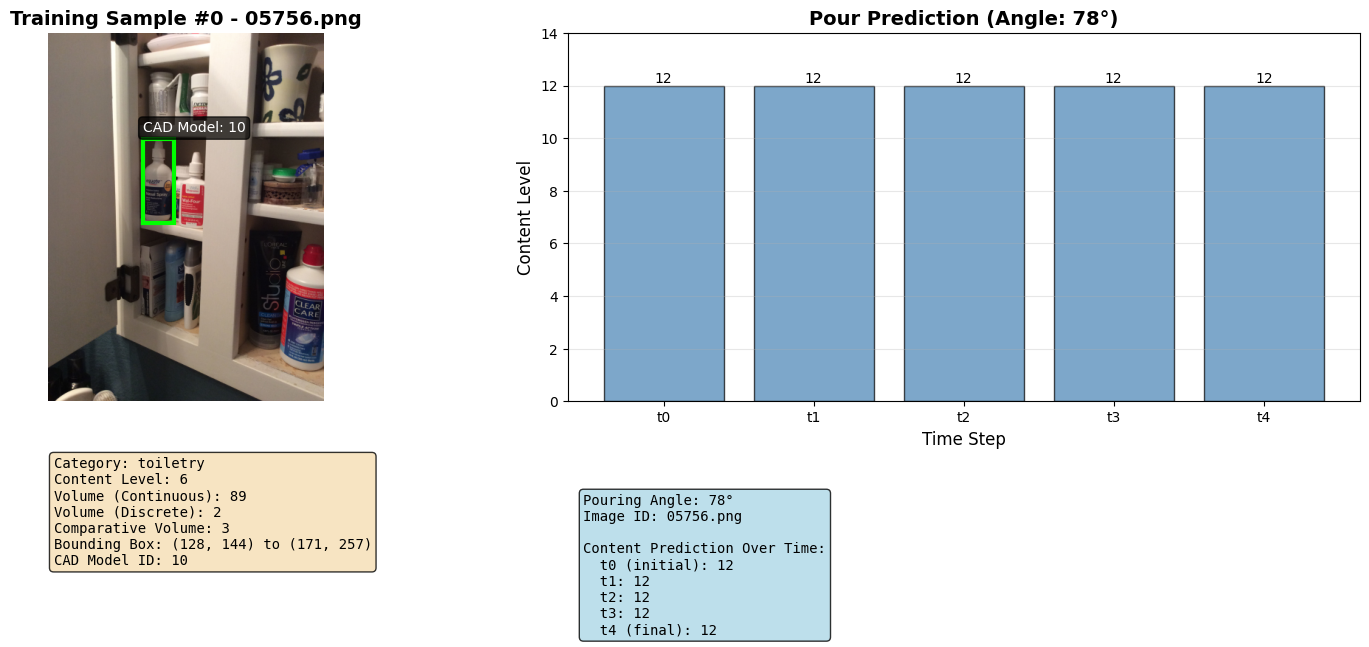


--- Sample #10: dinnerware ---


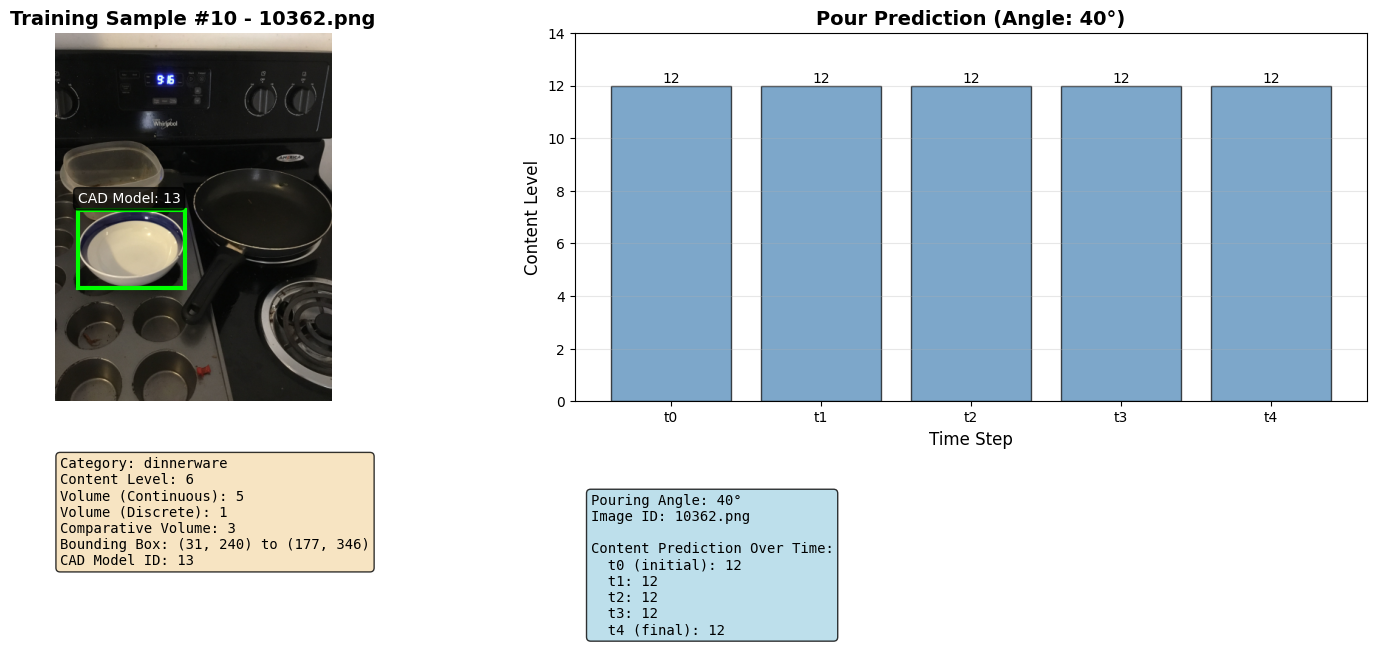


--- Sample #20: bottle ---


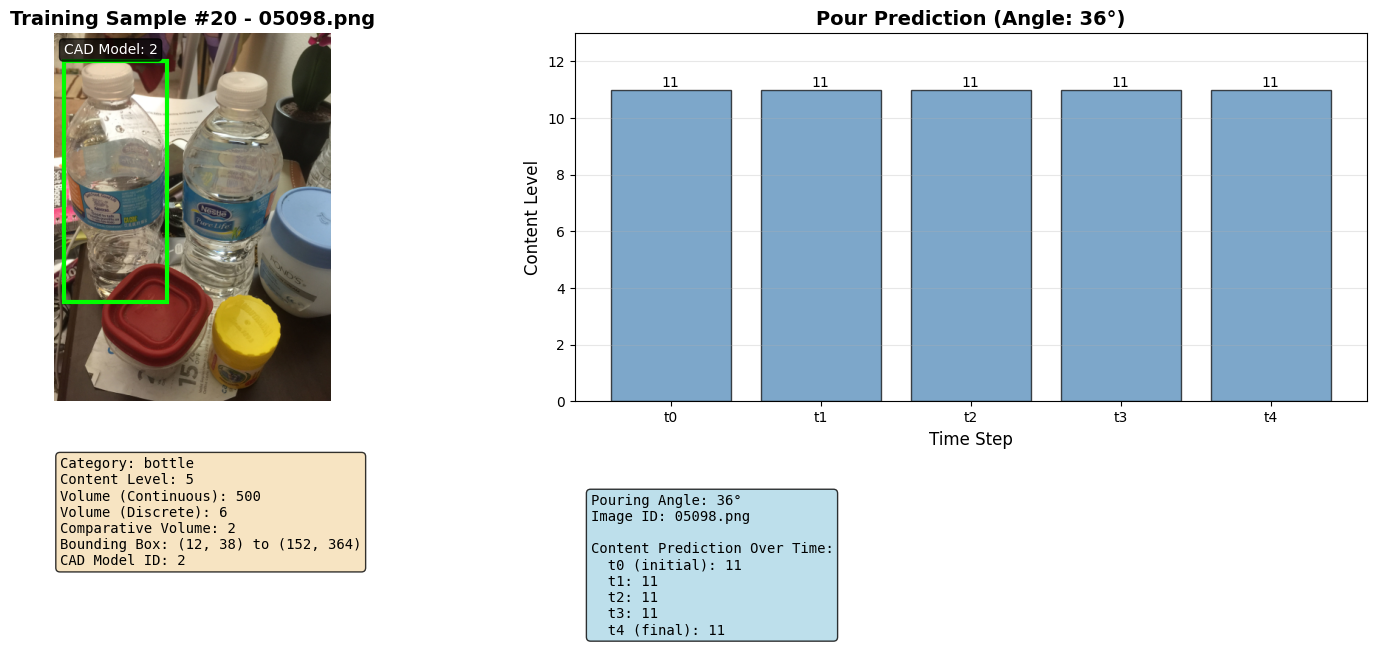


--- Sample #30: bottle ---


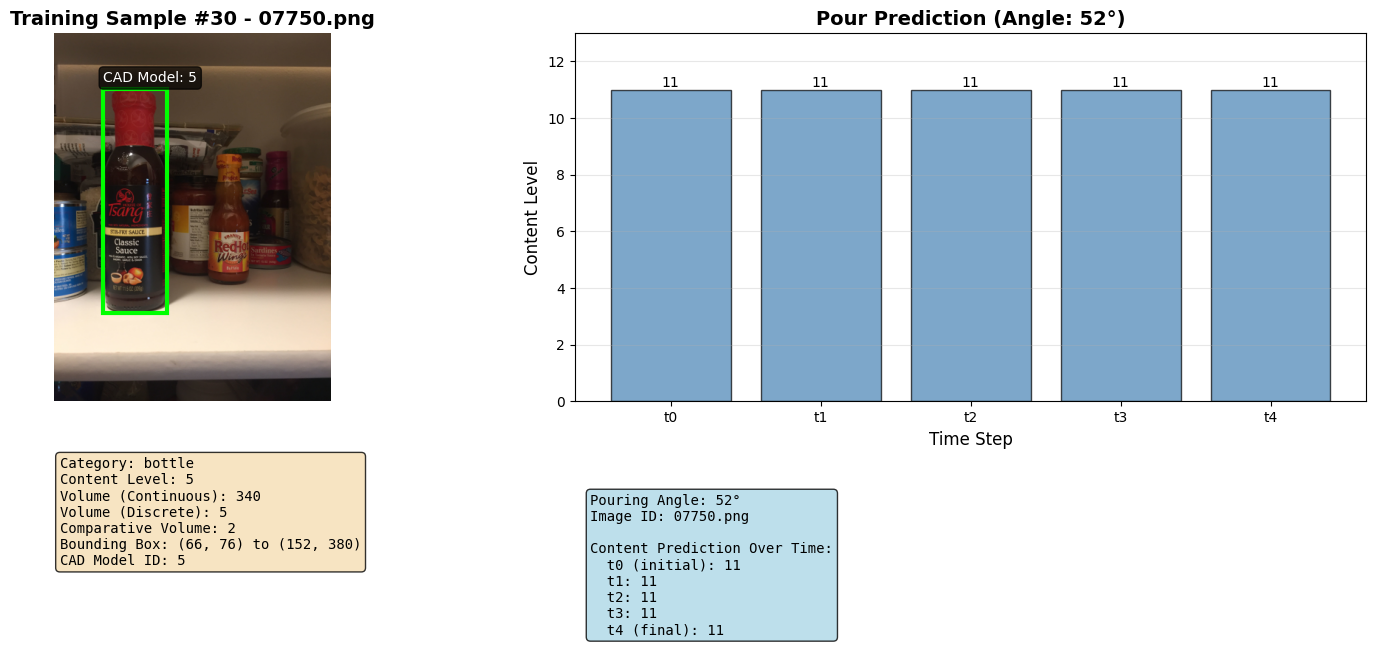


--- Sample #40: bottle ---


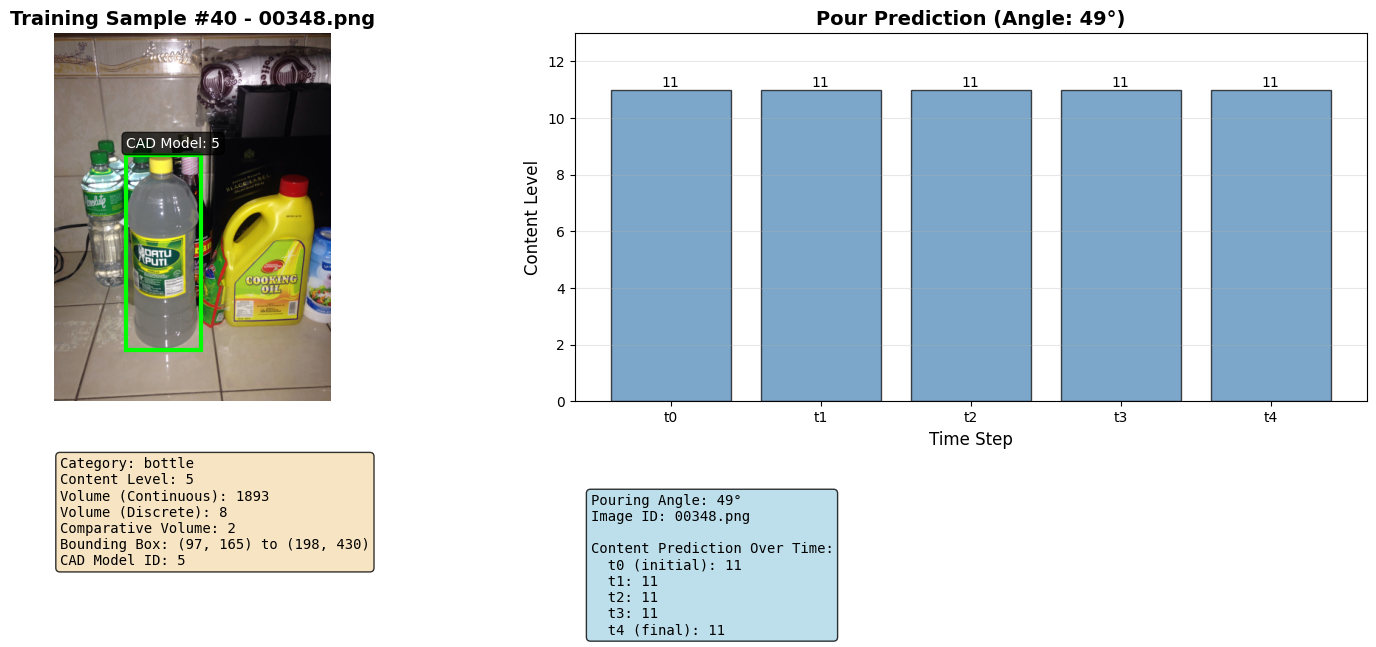

In [9]:
# Visualize multiple training samples
print("=== Multiple Training Samples ===\n")

# Select diverse samples (different categories or content levels)
sample_indices = [0, 10, 20, 30, 40]

for idx in sample_indices:
    if idx < len(train_data):
        sample = train_data[idx]
        pour_sample = find_pour_sample(sample["image_id"], train_pour_data)
        print(f"\n--- Sample #{idx}: {sample.get('category', 'N/A')} ---")
        visualize_sample(sample, pour_sample, title_prefix=f"Training Sample #{idx}")

## CAD Models Information

Let's check what CAD models are available in the dataset.

In [10]:
# List available CAD models
cad_model_files = sorted(cad_models_dir.glob("*.zip"))

print(f"=== CAD Models ===")
print(f"Total CAD model files: {len(cad_model_files)}\n")

print("Available CAD model archives:")
for cad_file in cad_model_files:
    file_size = cad_file.stat().st_size / (1024 * 1024)  # Convert to MB
    print(f"  {cad_file.name}: {file_size:.2f} MB")

print(f"\nCAD model IDs used in annotations: {sorted(cad_models)}")
print(f"Note: CAD models are stored as ZIP archives. Extract them to visualize 3D models.")

=== CAD Models ===
Total CAD model files: 34

Available CAD model archives:
  1.zip: 0.16 MB
  10.zip: 0.07 MB
  11.zip: 0.07 MB
  12.zip: 0.21 MB
  13.zip: 0.03 MB
  14.zip: 0.03 MB
  15.zip: 0.04 MB
  16.zip: 0.00 MB
  17.zip: 0.00 MB
  18.zip: 0.06 MB
  19.zip: 0.03 MB
  2.zip: 0.05 MB
  20.zip: 0.12 MB
  21.zip: 0.49 MB
  22.zip: 0.14 MB
  23.zip: 0.36 MB
  24.zip: 0.02 MB
  25.zip: 0.52 MB
  26.zip: 0.02 MB
  27.zip: 0.03 MB
  28.zip: 0.08 MB
  29.zip: 0.05 MB
  3.zip: 0.15 MB
  30.zip: 0.01 MB
  31.zip: 0.07 MB
  32.zip: 0.22 MB
  33.zip: 0.23 MB
  34.zip: 0.21 MB
  4.zip: 0.14 MB
  5.zip: 0.09 MB
  6.zip: 0.05 MB
  7.zip: 0.04 MB
  8.zip: 0.03 MB
  9.zip: 0.01 MB

CAD model IDs used in annotations: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34]
Note: CAD models are stored as ZIP archives. Extract them to visualize 3D models.


## Content Distribution Analysis

Analyze the distribution of content levels across the dataset.

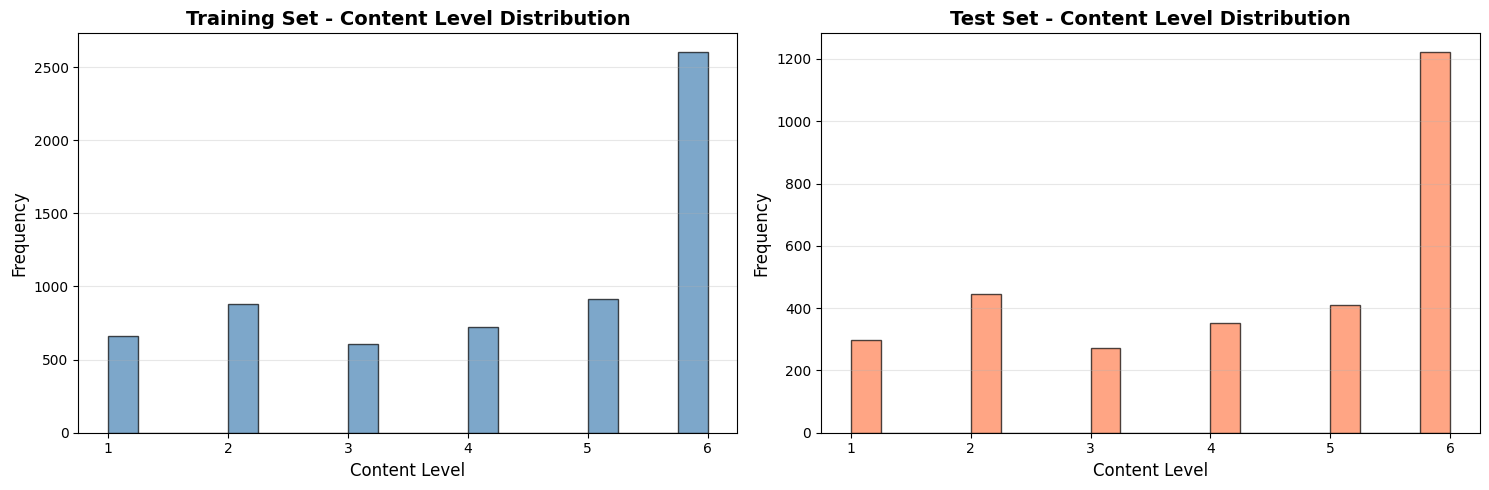

Training set - Content range: 1 to 6, Mean: 4.28
Test set - Content range: 1 to 6, Mean: 4.27


In [11]:
# Analyze content distribution
train_content = [s.get('content', 0) for s in train_data]
test_content = [s.get('content', 0) for s in test_data]

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Training set distribution
axes[0].hist(train_content, bins=20, color='steelblue', alpha=0.7, edgecolor='black')
axes[0].set_xlabel('Content Level', fontsize=12)
axes[0].set_ylabel('Frequency', fontsize=12)
axes[0].set_title('Training Set - Content Level Distribution', fontsize=14, fontweight='bold')
axes[0].grid(axis='y', alpha=0.3)

# Test set distribution
axes[1].hist(test_content, bins=20, color='coral', alpha=0.7, edgecolor='black')
axes[1].set_xlabel('Content Level', fontsize=12)
axes[1].set_ylabel('Frequency', fontsize=12)
axes[1].set_title('Test Set - Content Level Distribution', fontsize=14, fontweight='bold')
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Training set - Content range: {min(train_content)} to {max(train_content)}, Mean: {np.mean(train_content):.2f}")
print(f"Test set - Content range: {min(test_content)} to {max(test_content)}, Mean: {np.mean(test_content):.2f}")

## Volume Analysis

Analyze the continuous and discrete volume distributions.

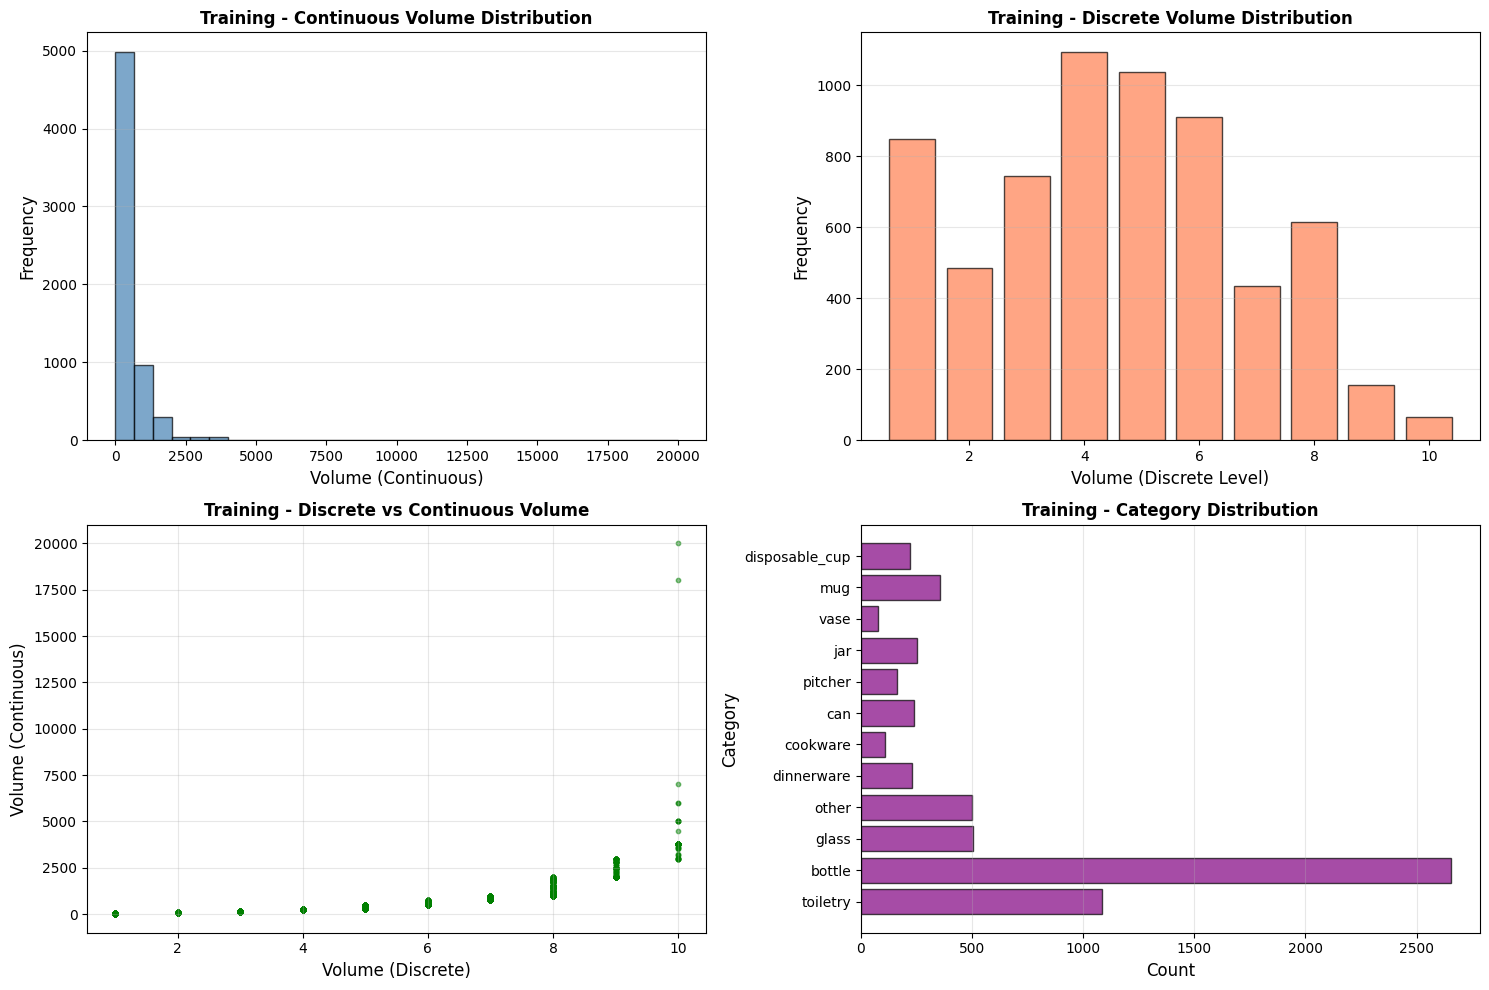

In [12]:
# Extract volume data
train_vol_cont = [s.get('volume_continuous', 0) for s in train_data]
train_vol_disc = [s.get('volume_discrete', 0) for s in train_data]

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Continuous volume - training
axes[0, 0].hist(train_vol_cont, bins=30, color='steelblue', alpha=0.7, edgecolor='black')
axes[0, 0].set_xlabel('Volume (Continuous)', fontsize=12)
axes[0, 0].set_ylabel('Frequency', fontsize=12)
axes[0, 0].set_title('Training - Continuous Volume Distribution', fontsize=12, fontweight='bold')
axes[0, 0].grid(axis='y', alpha=0.3)

# Discrete volume - training
vol_disc_counts = {}
for v in train_vol_disc:
    vol_disc_counts[v] = vol_disc_counts.get(v, 0) + 1
axes[0, 1].bar(sorted(vol_disc_counts.keys()), [vol_disc_counts[k] for k in sorted(vol_disc_counts.keys())],
              color='coral', alpha=0.7, edgecolor='black')
axes[0, 1].set_xlabel('Volume (Discrete Level)', fontsize=12)
axes[0, 1].set_ylabel('Frequency', fontsize=12)
axes[0, 1].set_title('Training - Discrete Volume Distribution', fontsize=12, fontweight='bold')
axes[0, 1].grid(axis='y', alpha=0.3)

# Scatter: continuous vs discrete
axes[1, 0].scatter(train_vol_disc, train_vol_cont, alpha=0.5, s=10, color='green')
axes[1, 0].set_xlabel('Volume (Discrete)', fontsize=12)
axes[1, 0].set_ylabel('Volume (Continuous)', fontsize=12)
axes[1, 0].set_title('Training - Discrete vs Continuous Volume', fontsize=12, fontweight='bold')
axes[1, 0].grid(alpha=0.3)

# Category distribution
cat_counts = {}
for s in train_data:
    cat = s.get('category', 'unknown')
    cat_counts[cat] = cat_counts.get(cat, 0) + 1

axes[1, 1].barh(list(cat_counts.keys()), list(cat_counts.values()), 
               color='purple', alpha=0.7, edgecolor='black')
axes[1, 1].set_xlabel('Count', fontsize=12)
axes[1, 1].set_ylabel('Category', fontsize=12)
axes[1, 1].set_title('Training - Category Distribution', fontsize=12, fontweight='bold')
axes[1, 1].grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

## Interactive Sample Explorer

Modify the index below to explore different samples interactively.

=== TRAIN Sample #15 ===
{
  "cad_model": 11,
  "category": "bottle",
  "comparative_vol": 3,
  "content": 5,
  "image_id": "08265.png",
  "volume_continuous": 237,
  "volume_discrete": 4,
  "x1": 199,
  "x2": 282,
  "y1": 121,
  "y2": 358
}

Pour Prediction Data:
{
  "angle": 98,
  "image_id": "08265.png",
  "t0_content": 11,
  "t1_content": 11,
  "t2_content": 11,
  "t3_content": 6,
  "t4_content": 2
}


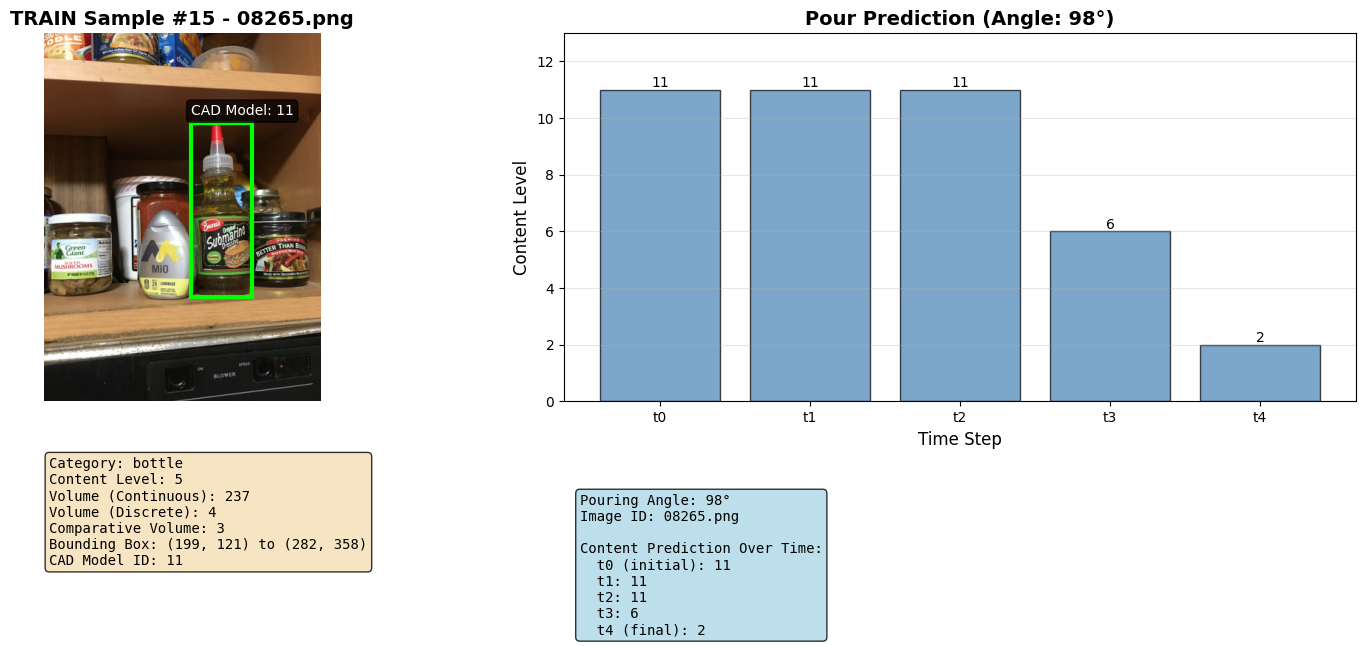

In [13]:
def explore_sample(sample_idx, dataset="train"):
    """
    Explore a specific sample from the dataset.
    
    Parameters:
    - sample_idx: Index of the sample to visualize
    - dataset: "train" or "test"
    """
    if dataset == "train":
        data = train_data
        pour_data = train_pour_data
    else:
        data = test_data
        pour_data = test_pour_data
    
    if sample_idx >= len(data):
        print(f"Error: Index {sample_idx} out of range. Max index: {len(data)-1}")
        return
    
    sample = data[sample_idx]
    pour_sample = find_pour_sample(sample["image_id"], pour_data)
    
    print(f"=== {dataset.upper()} Sample #{sample_idx} ===")
    print(json.dumps(sample, indent=2))
    if pour_sample:
        print("\nPour Prediction Data:")
        print(json.dumps(pour_sample, indent=2))
    
    visualize_sample(sample, pour_sample, 
                    title_prefix=f"{dataset.upper()} Sample #{sample_idx}")

# Example: Explore different samples
# Change these values to explore different samples
explore_sample(15, dataset="train")

## Summary

### Dataset Overview:
- **Purpose**: Container and quantity estimation with pouring dynamics
- **Tasks**: 
  - Object detection (bounding boxes)
  - Volume estimation (discrete and continuous)
  - Category classification
  - Pour prediction (temporal content changes)
  
### Key Features:
- High-quality RGB images of various containers
- Detailed annotations including bounding boxes and volume levels
- Temporal pour prediction data with multi-step content tracking
- CAD models for 3D container representations
- Multiple container categories (bottle, toiletry, etc.)

### Use Cases:
- Robot manipulation and pouring tasks
- Volume estimation from visual input
- Container recognition and classification
- Liquid dynamics prediction
- Vision-based quantity measurement

---

**Note**: To fully explore this dataset, you can:
1. Modify sample indices in the cells above
2. Extract and visualize CAD models using appropriate 3D visualization tools
3. Analyze specific categories or content ranges
4. Compare training and test set distributions